# Heart Disease Classification

**Author:** Dingyu Zhang | Waseda University, School of International Liberal Studies

A revised course project comparing interpretable linear models and tree ensembles on a public tabular dataset. The target is the dataset's `HeartDisease` label; this is not a model of future heart failure.

This version moves all learned preprocessing inside the training pipeline and selects a model using training-only cross-validation. The original course notebook informed this revision; its preprocessing approach also drew on group discussion. Repository preparation and methodological revision were assisted by ChatGPT. External data and libraries are credited below.

**Evaluation caveat:** the original project already inspected the seed-42 test partition. This revision reuses it for traceability, so its final score is a descriptive holdout result, not a pristine independent confirmation. A new external dataset is needed to establish generalization.


## 1. Setup and data

Run from the repository root. Download version 1 of [fedesoriano/heart-failure-prediction](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction) and place `heart.csv` in `data/`, or run `python download_data.py`. Raw data are excluded from this repository. Fixed seeds and the data SHA-256 support reproducibility.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

SEED = 42
ROOT = Path.cwd()
for directory in ['results', 'figures']:
    (ROOT / directory).mkdir(exist_ok=True)
data_path = ROOT / 'data' / 'heart.csv'
if not data_path.exists():
    raise FileNotFoundError('Place heart.csv in data/ or run python download_data.py first.')
data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
df = pd.read_csv(data_path)
print(f'Dataset: {df.shape[0]} rows, {df.shape[1]} columns')
print('SHA-256:', data_hash)
assert set(df['HeartDisease'].unique()) == {0, 1}
assert len(df) == 918, 'Expected Kaggle dataset version 1 (918 rows).'
print('Exact duplicate rows:', int(df.duplicated().sum()))


Dataset: 918 rows, 12 columns
SHA-256: 948420b084d8a3a0ca42b8419fce9aee175879e43f8aedf712377899a67aa49b
Exact duplicate rows: 0


## 2. Split before learning preprocessing

Zero `Cholesterol` and `RestingBP` values are treated as missing by a fixed rule. This rule does not estimate anything from the data. Median imputation, category vocabularies and scaling are learned only within training folds. The test partition is not used for model or hyperparameter selection.


In [2]:
numeric = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
categorical = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
X = df[numeric + categorical].copy()
y = df['HeartDisease'].copy()
for column in ['Cholesterol', 'RestingBP']:
    X[column] = X[column].replace(0, np.nan)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))
print('Training positive fraction:', round(float(y_train.mean()), 4))

summary = X_train[numeric].describe().T
summary.to_csv(ROOT / 'results' / 'training_summary.csv')
print(summary.round(2).to_string())


Training rows: 734 | Test rows: 184
Training positive fraction: 0.5531
             count    mean    std   min    25%    50%    75%    max
Age          734.0   53.85   9.44  29.0   47.0   55.0   61.0   77.0
RestingBP    734.0  132.87  18.08  92.0  120.0  130.0  141.0  200.0
Cholesterol  605.0  246.56  59.66  85.0  210.0  238.0  277.0  603.0
FastingBS    734.0    0.23   0.42   0.0    0.0    0.0    0.0    1.0
MaxHR        734.0  136.38  25.83  60.0  119.0  138.0  156.0  202.0
Oldpeak      734.0    0.87   1.06  -2.6    0.0    0.5    1.5    5.6


## 3. Compare candidate models with training-only cross-validation

The same five stratified folds are used for every candidate. Mean validation ROC-AUC is the predeclared selection criterion; ties use candidate order. Accuracy, F1 and recall are also recorded. The decision threshold remains 0.5. This is a modest candidate search, not an exhaustive optimization. CV standard deviations describe fold variation, not confidence intervals.


In [3]:
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())]), numeric),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
])
pipeline = Pipeline([('preprocessor', preprocessor),
                     ('model', DummyClassifier(strategy='most_frequent'))])
grid = [
    {'model': [DummyClassifier(strategy='most_frequent')]},
    {'model': [DecisionTreeClassifier(random_state=SEED, min_samples_leaf=10)],
     'model__max_depth': [3, 4]},
    {'model': [RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)],
     'model__min_samples_leaf': [3, 5]},
    {'model': [XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8,
                             eval_metric='logloss', random_state=SEED, n_jobs=1)]},
    {'model': [LogisticRegression(solver='liblinear', max_iter=5000, random_state=SEED)],
     'model__C': [0.1, 1.0, 10.0]},
    {'model': [LogisticRegression(solver='liblinear', l1_ratio=1.0,
                                  max_iter=5000, random_state=SEED)],
     'model__C': [0.1, 1.0, 10.0]}
]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(pipeline, grid, cv=cv, scoring={
    'roc_auc':'roc_auc', 'accuracy':'accuracy', 'f1':'f1', 'recall':'recall'},
    refit='roc_auc', n_jobs=1, error_score='raise')
search.fit(X_train, y_train)

def model_label(model):
    if isinstance(model, LogisticRegression):
        return 'Logistic Regression (L1)' if model.l1_ratio == 1.0 else 'Logistic Regression (L2)'
    return type(model).__name__

rows = []
for i, params in enumerate(search.cv_results_['params']):
    rows.append({
        'model': model_label(params['model']),
        'parameters': json.dumps({k: v for k,v in params.items() if k != 'model'}),
        **{name: float(search.cv_results_[name][i]) for name in [
            'mean_test_roc_auc', 'std_test_roc_auc', 'mean_test_accuracy',
            'mean_test_f1', 'mean_test_recall']}})
cv_results = pd.DataFrame(rows).sort_values('mean_test_roc_auc', ascending=False, kind='stable')
cv_results.to_csv(ROOT / 'results' / 'cv_results.csv', index=False)
print(cv_results.round(4).to_string(index=False))
best_model = search.best_estimator_
winner = model_label(best_model.named_steps['model'])
print('Selected using CV:', winner)


                   model                     parameters  mean_test_roc_auc  std_test_roc_auc  mean_test_accuracy  mean_test_f1  mean_test_recall
           XGBClassifier                             {}             0.9319            0.0278              0.8665        0.8800            0.8818
  RandomForestClassifier {"model__min_samples_leaf": 3}             0.9316            0.0258              0.8474        0.8666            0.8917
  RandomForestClassifier {"model__min_samples_leaf": 5}             0.9302            0.0291              0.8474        0.8660            0.8893
Logistic Regression (L1)              {"model__C": 1.0}             0.9229            0.0344              0.8474        0.8638            0.8695
Logistic Regression (L2)              {"model__C": 1.0}             0.9221            0.0338              0.8474        0.8633            0.8671
Logistic Regression (L1)              {"model__C": 0.1}             0.9218            0.0327              0.8502        0.8676    

## 4. Final descriptive holdout evaluation

Only the selected fitted pipeline is evaluated here, alongside the majority-class baseline. No model switching or threshold changes follow this step. Because this historical partition was examined in the original coursework, interpret the results with the caveat at the top of this notebook.


            model  accuracy  precision  recall     f1  roc_auc
Majority baseline    0.5543     0.5543  1.0000 0.7133   0.5000
    XGBClassifier    0.8696     0.8824  0.8824 0.8824   0.9315


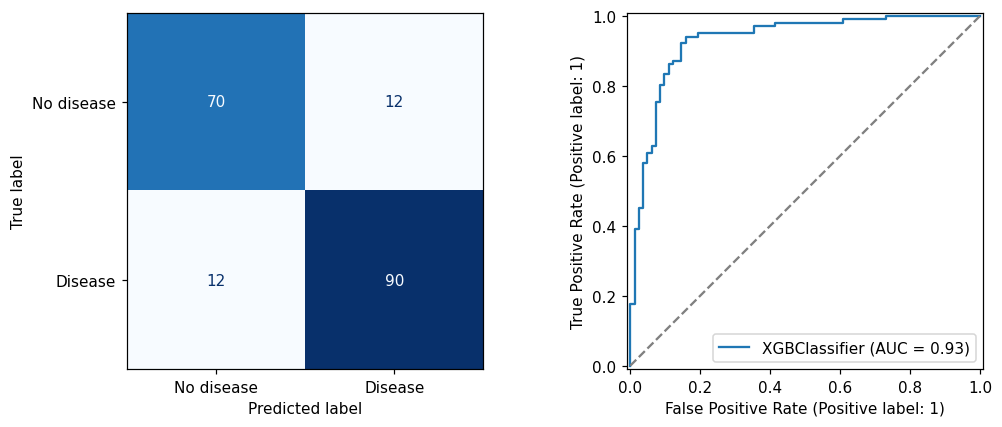

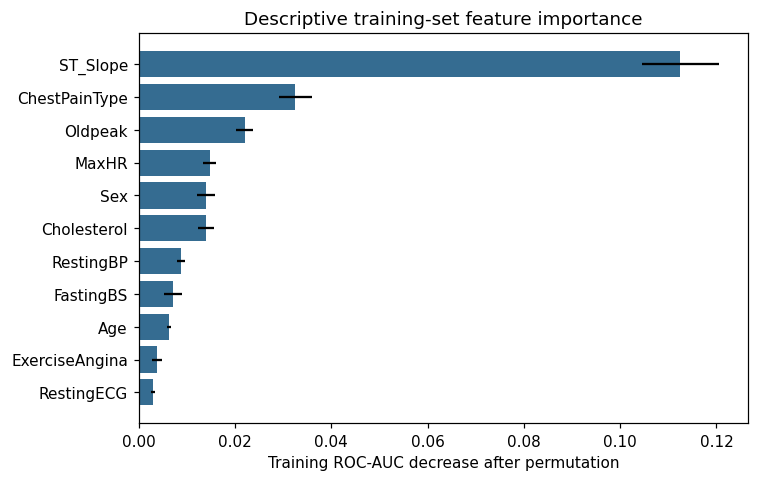

In [4]:
def metrics(model):
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]
    return dict(accuracy=float(accuracy_score(y_test,pred)),
                precision=float(precision_score(y_test,pred,zero_division=0)),
                recall=float(recall_score(y_test,pred,zero_division=0)),
                f1=float(f1_score(y_test,pred,zero_division=0)),
                roc_auc=float(roc_auc_score(y_test,score)))

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
holdout = pd.DataFrame([{'model':'Majority baseline', **metrics(baseline)},
                        {'model':winner, **metrics(best_model)}])
holdout.to_csv(ROOT / 'results' / 'holdout_metrics.csv', index=False)
print(holdout.round(4).to_string(index=False))
fig, axes = plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, ax=axes[0],
    display_labels=['No disease', 'Disease'], cmap='Blues', colorbar=False)
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1],name=winner)
axes[1].plot([0,1],[0,1],'--',color='gray')
fig.tight_layout()
fig.savefig(ROOT / 'figures' / 'holdout_evaluation.png', dpi=160)
plt.show()

# Training-set permutation importance is descriptive, not an independent validation.
importance = permutation_importance(best_model, X_train, y_train,
    scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=1)
feature_importance = pd.DataFrame({'feature':X_train.columns,
    'mean_auc_decrease':importance.importances_mean,
    'std_auc_decrease':importance.importances_std}).sort_values('mean_auc_decrease')
feature_importance.to_csv(ROOT / 'results' / 'training_permutation_importance.csv',index=False)
fig,ax = plt.subplots(figsize=(7,4.5))
ax.barh(feature_importance['feature'],feature_importance['mean_auc_decrease'],
        xerr=feature_importance['std_auc_decrease'],color='#356c91')
ax.set_xlabel('Training ROC-AUC decrease after permutation')
ax.set_title('Descriptive training-set feature importance')
fig.tight_layout()
fig.savefig(ROOT / 'figures' / 'feature_importance.png',dpi=160)
plt.show()

metadata = {
    'seed':SEED,'dataset':'fedesoriano/heart-failure-prediction','dataset_version':1,
    'data_sha256':data_hash,'rows':len(df),'train_rows':len(X_train),'test_rows':len(X_test),
    'selected_model':winner,'best_cv_roc_auc':float(search.best_score_),
    'selected_parameters':{k:v for k,v in search.best_params_.items() if k!='model'},
    'test_partition_previously_inspected':True,
    'python':platform.python_version(),
    'packages':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','xgboost']}}
(ROOT/'results'/'run_metadata.json').write_text(json.dumps(metadata,indent=2)+'\n')


## Recorded run

The training-only search selected XGBoost (mean CV ROC-AUC **0.9319**, fold SD **0.0278**). The random forest candidate was very close (**0.9316**); this difference does not establish superiority. On the historical holdout (184 rows), the selected model achieved accuracy **0.8696**, F1 **0.8824**, recall **0.8824**, and ROC-AUC **0.9315**. The majority baseline accuracy was **0.5543** and ROC-AUC **0.5000**. These values describe this fixed split and environment; they are not clinical validation.


## 5. Interpretation and limitations

- Use the generated CV table to explain model selection, and the holdout table to describe the selected model's performance. Small numerical differences do not establish meaningful superiority.
- This dataset combines historical source datasets; patient overlap and source-specific effects may remain even if exact duplicate rows are absent. Patient/source identifiers are not available here for grouped validation.
- Median imputation is a practical baseline and may hide informative missingness. A future extension could compare missingness indicators within training-only CV.
- Importance measures reflect predictive associations, not medical causes. Training-set importance may be optimistic and correlated features can share importance.
- This educational analysis is not clinically validated. It does not establish future-risk prediction, fairness, calibration or usefulness in clinical decisions.
- The old accuracy/AUC values are intentionally not carried forward as results of this revised procedure.

## Sources and acknowledgment

Data: [fedesoriano, Heart Failure Prediction Dataset, version 1](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction). Consult the original dataset page for provenance and reuse terms; this repository does not redistribute `heart.csv`.

Methods and software: [scikit-learn](https://scikit-learn.org/stable/), [XGBoost](https://xgboost.readthedocs.io/), pandas, NumPy and Matplotlib. Initial preprocessing was informed by a classmate's approach and group discussion. The source course notebook is by Dingyu Zhang; this public revision reorganizes that work with AI-assisted editing and evaluation corrections.
